# 04 – Detecção de condição anormal sem rótulos (braço principal)

**Ideia:** treinar só com dados **normais** do início da base (antes da primeira falha), definir o limiar numa janela normal de **validação**, e avaliar nas 4 falhas reportadas. O limiar vem só da validação (percentil dos scores): **não usa nenhum rótulo nem minuto do teste**, então pode ser implantado.

- **Variantes do pipeline:** E0 (10 s, sem qualidade, features pontuais), E1 (Silver de 1 min, features pontuais), E2 (+ janelas por tempo de 1 h e 6 h).
- **Modelos:** Isolation Forest e distância de Mahalanobis (com encolhimento de Ledoit-Wolf).
- **Avaliação:** nos mesmos minutos para todas as variantes (os da E2), excluindo as 24 h depois de cada falha (recuperação pós-reparo). Para a E0, os scores são agregados por minuto (média).
- **Métricas:** eventos detectados (de 4), atraso até o primeiro alarme, fração dos minutos da falha em alarme, falsos alarmes por dia, e PR-AUC/lift com baseline de acaso (rotação circular).
- **Limiar:** percentil 99,9 da validação definido **antes** de ver o teste; 99 e 99,5 entram como sensibilidade.
- **E4 mínima:** ablação por grupos de sensores (seção 6).

Resultados descritivos: 4 eventos, sem teste de significância.

In [1]:
import json
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import config
from detection import (
    anomaly_scores, evaluate_detection, in_failure, post_failure_mask, pr_auc_with_null, window_features,
)
from evaluation import alarm_episodes

# --- Parâmetros ---------------------------------------------------------------
WINDOWS = [60, 360]          # minutos (E2)
MIN_COVERAGE = 0.8
TRAIN_FRACTION = 0.7         # fração do período normal inicial usada no treino
VAL_MARGIN_DAYS = 1          # a validação termina este número de dias antes da primeira falha
EMBARGO_H = 24               # horas pós-falha excluídas da avaliação
QUANTILES = [99.0, 99.5, 99.9]
PRIMARY_Q = 99.9             # definido antes de ver o teste
MODELS = ["IsolationForest", "Mahalanobis"]
N_SHIFTS = 200
SEED = config.SEED


## 1. Falhas e dados

In [2]:
rep = pd.read_csv(config.FAILURE_REPORT, parse_dates=["start_time", "end_time"]).sort_values("start_time")
failures = [
    {"id": int(r.failure_id), "start": r.start_time.to_pydatetime(), "end": r.end_time.to_pydatetime()}
    for r in rep.itertuples()
]

def load_silver(variant):
    d = config.SILVER_DIR / variant
    groups = json.loads((d / "_columns.json").read_text(encoding="utf-8"))
    df = pd.read_parquet(d)
    df["ts"] = pd.to_datetime(df["ts"]).dt.tz_localize(None)
    return df.sort_values("ts").reset_index(drop=True), groups["analog"], groups["digital"]

sil1, analog, digital = load_silver("e1")
sil0, _, _ = load_silver("e0")
sensors = analog + digital

# Rótulo e exclusão pós-falha no eixo de 1 min
lab_ts = sil1["ts"]
label_map = pd.Series(in_failure(lab_ts, failures), index=lab_ts)
excl_map = pd.Series(post_failure_mask(lab_ts, failures, EMBARGO_H), index=lab_ts)

# Features por variante
feat2 = window_features(sil1, analog, digital, WINDOWS, MIN_COVERAGE)
e2 = feat2[feat2["coverage_ok"]].drop(columns="coverage_ok").reset_index(drop=True)
FRAMES = {"E0": sil0[["ts"] + sensors], "E1": sil1[["ts"] + sensors], "E2": e2}
FEATS = {"E0": sensors, "E1": sensors, "E2": [c for c in e2.columns if c != "ts"]}
for k, v in FRAMES.items():
    assert not v[FEATS[k]].isna().any().any(), f"{k}: nulos nas features"
    print(f"{k}: {len(v):>9,} linhas | {len(FEATS[k])} features")

common_ts = set(e2["ts"])        # população comum de avaliação (minutos da E2)
print("Minutos comuns:", len(common_ts))

E0: 1,516,948 linhas | 15 features
E1:   252,382 linhas | 15 features
E2:   216,560 linhas | 59 features
Minutos comuns: 216560


## 2. Divisão treino / validação / teste

O período anterior à primeira falha é o único sem falhas: treino (início) e validação (fim, normal) saem dele; o teste vai até o fim da base e contém as 4 falhas.

In [3]:
t0 = sil1["ts"].min()
f1 = pd.Timestamp(failures[0]["start"])
train_end = (t0 + (f1 - t0) * TRAIN_FRACTION).floor("D")
val_end = (f1 - pd.Timedelta(days=VAL_MARGIN_DAYS)).floor("D")
print("Treino  :", t0, "->", train_end)
print("Validação:", train_end, "->", val_end)
print("Teste    :", val_end, "->", sil1["ts"].max())
assert train_end < val_end, "ajuste TRAIN_FRACTION / VAL_MARGIN_DAYS"

def split(df):
    return (df[df["ts"] < train_end], df[(df["ts"] >= train_end) & (df["ts"] < val_end)], df[df["ts"] >= val_end])

for k, v in FRAMES.items():
    tr, va, te = split(v)
    print(f"{k}: treino {len(tr):,} | validação {len(va):,} | teste {len(te):,}")

Treino  : 2020-02-01 00:00:00 -> 2020-03-25 00:00:00
Validação: 2020-03-25 00:00:00 -> 2020-04-17 00:00:00
Teste    : 2020-04-17 00:00:00 -> 2020-09-01 03:59:00
E0: treino 393,791 | validação 162,472 | teste 960,685
E1: treino 65,052 | validação 26,848 | teste 160,482
E2: treino 56,416 | validação 22,895 | teste 137,249


## 3. Pontuação e avaliação

In [4]:
def to_minute(ts, score):
    s = pd.DataFrame({"ts": pd.Series(ts).dt.floor("min").to_numpy(), "score": score})
    return s.groupby("ts", as_index=False)["score"].mean()

def run(frame, feats, model, per_minute_agg=False, with_pr=True):
    tr, va, te = split(frame)
    sc = anomaly_scores(model, tr[feats], {"val": va[feats], "test": te[feats]}, seed=SEED)
    val_s = pd.DataFrame({"ts": va["ts"].to_numpy(), "score": sc["val"]})
    test_s = pd.DataFrame({"ts": te["ts"].to_numpy(), "score": sc["test"]})
    if per_minute_agg:
        val_s, test_s = to_minute(val_s["ts"], val_s["score"]), to_minute(test_s["ts"], test_s["score"])
    t = test_s[test_s["ts"].isin(common_ts)].copy()
    t["label"] = t["ts"].map(label_map).astype(int)
    t = t[~t["ts"].map(excl_map).fillna(False).astype(bool)].reset_index(drop=True)
    out = {"t": t, "thr": {q: float(np.quantile(val_s["score"], q / 100)) for q in QUANTILES}}
    out["pr"] = pr_auc_with_null(t, N_SHIFTS, SEED) if with_pr else {}
    return out

events_rows, global_rows, store = [], [], {}
for variant, frame in FRAMES.items():
    for model in MODELS:
        r = run(frame, FEATS[variant], model, per_minute_agg=(variant == "E0"))
        store[(variant, model)] = r
        for q, thr in r["thr"].items():
            ev, g = evaluate_detection(r["t"], thr, failures)
            ev.insert(0, "quantil", q); ev.insert(0, "modelo", model); ev.insert(0, "variante", variant)
            events_rows.append(ev)
            global_rows.append({
                "variante": variant, "modelo": model, "quantil": q, **g, **r["pr"],
                "eventos_detectados": int(ev["detectada"].sum()),
                "atraso_mediano_h": ev["atraso_h"].median(),
                "recall_medio": ev["recall_minutos"].mean(),
            })
        print(variant, model, "concluído")

events = pd.concat(events_rows, ignore_index=True)
glob = pd.DataFrame(global_rows)

E0 IsolationForest concluído
E0 Mahalanobis concluído
E1 IsolationForest concluído
E1 Mahalanobis concluído
E2 IsolationForest concluído
E2 Mahalanobis concluído


## 4. Resultados

Leitura: **eventos_detectados** (de 4), **atraso_mediano_h**, **falsos_alarmes_por_dia** (no limiar da validação, sem usar o teste), **lift** e `p_pr_auc` (baixo = acima do acaso). O quantil de referência é o 99,9; os demais mostram a sensibilidade.

In [5]:
cols = ["variante", "modelo", "quantil", "eventos_detectados", "atraso_mediano_h", "recall_medio",
        "falsos_alarmes_por_dia", "pct_minutos_normais_em_alarme", "pr_auc", "lift", "p_pr_auc"]
glob[cols].round(3).sort_values(["quantil", "variante", "modelo"], ascending=[False, True, True])

,variante,modelo,quantil,eventos_detectados,atraso_mediano_h,recall_medio,falsos_alarmes_por_dia,pct_minutos_normais_em_alarme,pr_auc,lift,p_pr_auc
2,E0,IsolationForest,99.9,4,1.592,0.404,0.034,0.015,0.550,15.874,0.00
5,E0,Mahalanobis,99.9,1,0.083,0.000,0.089,0.020,0.069,1.983,0.13
8,E1,IsolationForest,99.9,3,0.733,0.019,2.984,0.004,0.354,10.221,0.00
11,E1,Mahalanobis,99.9,1,0.083,0.000,0.246,0.020,0.284,8.203,0.00
14,E2,IsolationForest,99.9,1,5.833,0.000,0.000,0.000,0.725,20.955,0.00
17,E2,Mahalanobis,99.9,4,3.233,0.628,0.156,0.084,0.270,7.789,0.00
1,E0,IsolationForest,99.5,4,0.358,0.576,0.101,0.015,0.550,15.874,0.00
4,E0,Mahalanobis,99.5,2,1.417,0.084,1.308,0.227,0.069,1.983,0.13
7,E1,IsolationForest,99.5,4,0.817,0.110,4.661,0.011,0.354,10.221,0.00
10,E1,Mahalanobis,99.5,4,0.000,0.825,0.503,0.215,0.284,8.203,0.00


In [6]:
ev_p = events[events["quantil"] == PRIMARY_Q]
print("Detecção por falha (limiar = percentil %.1f da validação):" % PRIMARY_Q)
display(ev_p.pivot_table(index=["variante", "modelo"], columns="falha", values="detectada").round(0))
print("Atraso até o primeiro alarme (h):")
display(ev_p.pivot_table(index=["variante", "modelo"], columns="falha", values="atraso_h").round(2))
print("Fração dos minutos da falha em alarme:")
display(ev_p.pivot_table(index=["variante", "modelo"], columns="falha", values="recall_minutos").round(2))

Detecção por falha (limiar = percentil 99.9 da validação):


falha                       1    2    3    4
variante modelo                             
E0       IsolationForest  1.0  1.0  1.0  1.0
         Mahalanobis      1.0  0.0  0.0  0.0
E1       IsolationForest  1.0  1.0  1.0  0.0
         Mahalanobis      1.0  0.0  0.0  0.0
E2       IsolationForest  1.0  0.0  0.0  0.0
         Mahalanobis      1.0  1.0  1.0  1.0

Atraso até o primeiro alarme (h):


falha                        1     2     3     4
variante modelo                                 
E0       IsolationForest  6.00  0.33  0.03  2.85
         Mahalanobis      0.08   NaN   NaN   NaN
E1       IsolationForest  0.73  1.27  0.37   NaN
         Mahalanobis      0.08   NaN   NaN   NaN
E2       IsolationForest  5.83   NaN   NaN   NaN
         Mahalanobis      0.00  4.17  3.33  3.13

Fração dos minutos da falha em alarme:


falha                        1     2     3     4
variante modelo                                 
E0       IsolationForest  0.01  0.50  0.93  0.19
         Mahalanobis      0.00  0.00  0.00  0.00
E1       IsolationForest  0.00  0.02  0.06  0.00
         Mahalanobis      0.00  0.00  0.00  0.00
E2       IsolationForest  0.00  0.00  0.00  0.00
         Mahalanobis      0.92  0.36  0.92  0.31

### Falsos alarmes por mês (deriva de regime)

O treino usa o início da base; o teste vai até meses depois. Se os falsos alarmes crescem com o tempo, o regime de operação mudou (deriva).

In [7]:
rows = []
for (variant, model), r in store.items():
    t, thr = r["t"], r["thr"][PRIMARY_Q]
    normal = t[t["label"] == 0]
    fa = normal[normal["score"] >= thr]
    ep = pd.Series([s for s, _ in alarm_episodes(fa["ts"])], dtype="datetime64[ns]")
    days = normal.groupby(normal["ts"].dt.to_period("M")).size() / 1440
    n_ep = ep.groupby(ep.dt.to_period("M")).size() if len(ep) else pd.Series(dtype=int)
    for month, d in days.items():
        rows.append({"variante": variant, "modelo": model, "mes": str(month),
                     "falsos_alarmes_por_dia": n_ep.get(month, 0) / d if d else np.nan})
drift = pd.DataFrame(rows).pivot_table(index=["variante", "modelo"], columns="mes", values="falsos_alarmes_por_dia").round(2)
drift

mes                       2020-04  2020-05  2020-06  2020-07  2020-08
variante modelo                                                      
E0       IsolationForest     0.00     0.10     0.00     0.05     0.00
         Mahalanobis         0.29     0.05     0.10     0.10     0.05
E1       IsolationForest     0.29     1.39     2.91     3.45     4.91
         Mahalanobis         0.44     0.62     0.10     0.19     0.05
E2       IsolationForest     0.00     0.00     0.00     0.00     0.00
         Mahalanobis         0.44     0.21     0.14     0.15     0.05

## 5. Scores ao longo do tempo (E1)

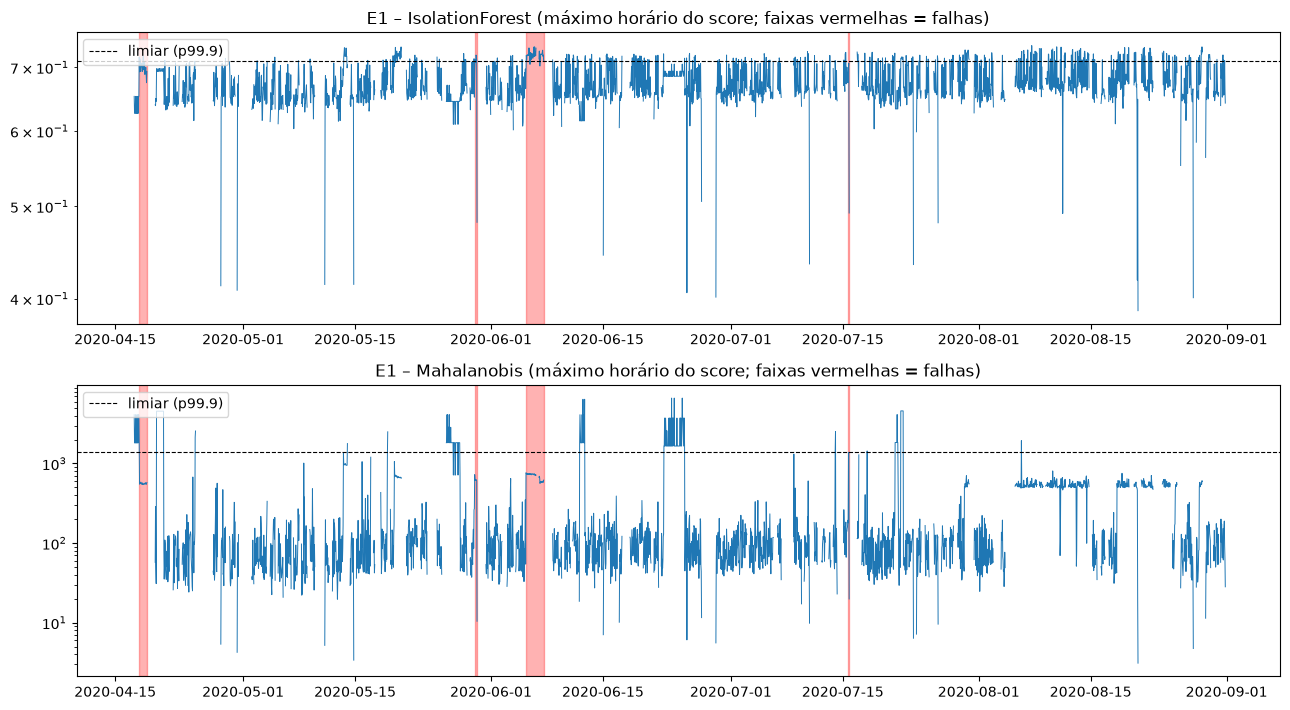

In [8]:
fig, axes = plt.subplots(len(MODELS), 1, figsize=(13, 3.6 * len(MODELS)), squeeze=False)
for ax, model in zip(axes[:, 0], MODELS):
    r = store[("E1", model)]
    t = r["t"].set_index("ts")["score"].resample("1h").max()
    ax.plot(t.index, t.values, lw=0.7)
    for f in failures:
        ax.axvspan(pd.Timestamp(f["start"]), pd.Timestamp(f["end"]), color="red", alpha=0.3)
    ax.axhline(r["thr"][PRIMARY_Q], color="k", ls="--", lw=0.8, label=f"limiar (p{PRIMARY_Q})")
    ax.set_title(f"E1 – {model} (máximo horário do score; faixas vermelhas = falhas)")
    ax.set_yscale("log"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 6. E4 mínima: ablação por grupos de sensores (E1)

Quais grupos de sensores sustentam a detecção? Para cada grupo: remover o grupo (`sem_*`) e usar só o grupo (`somente_*`).

In [9]:
GROUPS = {
    "pressao": [c for c in ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs"] if c in sensors],
    "temperatura": [c for c in ["Oil_temperature"] if c in sensors],
    "corrente": [c for c in ["Motor_current"] if c in sensors],
    "digitais": list(digital),
}
unassigned = set(sensors) - {c for g in GROUPS.values() for c in g}
if unassigned:
    print("Sensores fora dos grupos (ficam só em 'todos'):", unassigned)
GROUPS = {k: v for k, v in GROUPS.items() if v}

scenarios = {"todos": sensors}
for g, cols_ in GROUPS.items():
    scenarios[f"sem_{g}"] = [c for c in sensors if c not in cols_]
    scenarios[f"somente_{g}"] = cols_

abl = []
for name, cols_ in scenarios.items():
    if not cols_:
        continue
    for model in MODELS:
        r = run(FRAMES["E1"], cols_, model, with_pr=False)
        ev, g = evaluate_detection(r["t"], r["thr"][PRIMARY_Q], failures)
        abl.append({"cenario": name, "n_features": len(cols_), "modelo": model,
                    "eventos_detectados": int(ev["detectada"].sum()),
                    "atraso_mediano_h": ev["atraso_h"].median(),
                    "recall_medio": ev["recall_minutos"].mean(),
                    "falsos_alarmes_por_dia": g["falsos_alarmes_por_dia"]})
ablation = pd.DataFrame(abl).round(3)
ablation.sort_values(["modelo", "cenario"])

,cenario,n_features,modelo,eventos_detectados,atraso_mediano_h,recall_medio,falsos_alarmes_por_dia
10,sem_corrente,14,IsolationForest,3,0.733,0.010,2.839
14,sem_digitais,7,IsolationForest,3,0.333,0.490,0.335
2,sem_pressao,10,IsolationForest,3,0.733,0.004,2.917
6,sem_temperatura,14,IsolationForest,3,0.733,0.006,2.604
12,somente_corrente,1,IsolationForest,0,NaN,0.000,1.107
16,somente_digitais,8,IsolationForest,3,0.733,0.005,2.191
4,somente_pressao,5,IsolationForest,1,0.883,0.114,2.012
8,somente_temperatura,1,IsolationForest,0,NaN,0.000,0.000
0,todos,15,IsolationForest,3,0.733,0.019,2.984
11,sem_corrente,14,Mahalanobis,2,1.533,0.015,0.246


In [10]:
out = config.DOCS_DIR
out.mkdir(exist_ok=True)
events.to_csv(out / "resultados_sem_rotulos_eventos.csv", index=False)
glob.to_csv(out / "resultados_sem_rotulos_global.csv", index=False)
ablation.to_csv(out / "resultados_sem_rotulos_ablacao.csv", index=False)
drift.to_csv(out / "resultados_sem_rotulos_deriva.csv")
print("Resultados salvos em", out)

Resultados salvos em C:\workspace\Projeto-Integrador-CienciaDados-UTFPR\docs


- Quantos dos 4 eventos cada variante detecta no limiar de referência? No limiar 99,9, a contagem de “eventos detectados” por si só é enganosa, porque conta qualquer minuto dentro da falha. O E0 com IsolationForest dispara 9 minutos na falha 1, 194 na falha 2, 2.347 na falha 3 e 50 na falha 4; o E1 com Mahalanobis detecta só 2 minutos na falha 1. Só duas combinações têm cobertura substancial: E0 com IsolationForest (aproximadamente 0,6%, 50%, 93% e 19% dos minutos de cada falha) e E2 com Mahalanobis (92%, 36%, 92% e 31%).
- Atraso até o primeiro alarme: E0 × E1 × E2. O atraso mediano da E0 com IsolationForest é 1,59 h; na E1 é 0,73 h; na E2 é 5,83 h. O Mahalanobis tem 0,08 h na E0, 0,08 h na E1 e 3,23 h na E2, mas esse valor vem de poucos eventos e não é comparável entre combinações, porque cada uma detecta um conjunto diferente de falhas. O que se confirma é que as janelas atrasam o alarme.
- Isolation Forest × Mahalanobis: a comparação mudou bastante. No ranking sem depender do limiar, 5 das 6 combinações superam o acaso. O melhor é E2 com IsolationForest (PR-AUC 0,725, lift 21). A E0 com Mahalanobis fica no nível do acaso (p = 0,13), então o efeito de pipeline e algoritmo interage. A diferença entre modelos é relevante, mas não se pode resumir a “melhor ou pior” sem olhar o limiar e a cobertura.
- Falsos alarmes por mês: há deriva entre treino e teste. A E1 com IsolationForest cresce de 0,29 para 4,91 episódios por dia entre abril e agosto. A E2 com IsolationForest fica em zero em todos os meses, mas isso é um detector silencioso, não um detector robusto à deriva. O Mahalanobis em E2 mantém cerca de 0,15 episódios por dia, mas a fração de minutos normais em alarme sobe para 8,4%, bem acima do esperado (0,1%).
- Falsos alarmes por dia versus janelas: “janelas diminuem falsos alarmes” não se sustenta de forma geral. No Mahalanobis, os episódios caem de 0,25 para 0,16 por dia, mas a fração de minutos normais em alarme sobe de 2,0% para 8,4%. Os episódios escondem alarmes longos. No IsolationForest, a queda para zero vem junto com o colapso da detecção; a E2 não detecta falhas 2, 3 e 4. O que se confirma é que as janelas atrasam o alarme (3,1 a 5,8 h na E2, contra até 1,6 h nas outras).
- Ablação: o achado mais forte está nos sensores digitais. Remover os digitais melhora os dois modelos: no IsolationForest, a cobertura sobe de 0,019 para 0,490 e os falsos alarmes caem de 2,98 para 0,34 por dia; no Mahalanobis, a cobertura passa de 0,000 para 0,151 e os falsos alarmes ficam estáveis em 0,168 por dia. A temperatura do óleo, com o Mahalanobis, cobre 0,156 dos minutos sem falsos alarmes. Já dizer que “digitais sozinhos detectam 3/4” no IsolationForest é exagerado: a cobertura deles é de apenas 0,5% e a maior parte da detecção realmente vem do modelo que usa outras variáveis.
- Lembrar: 4 eventos e resultados descritivos. O que os dados mostram é que a E2 com IsolationForest lidera o ranking global, mas o limiar da validação é frágil; o percentil 99,9 pode ficar acima da maior parte dos minutos de falha, e há deriva entre validação e teste. A detecção real é sensível ao modelo, ao limiar e à janela de avaliação.